# Credit Scoring — Scorecard Analysis

Reads the saved validation-set predictions produced by Notebook 3 (Training &
Analysis), converts predicted default probabilities (PDs) to credit scores using
the industry-standard PDO (Points to Double the Odds) formula, and produces a
full scorecard analysis.

**Pipeline overview**
1. Configuration — PDO parameters, paths, score range
2. Load saved predictions from Notebook 3
3. Convert PDs → credit scores (PDO formula)
4. Assign risk bands (A–E)
5. Score band analysis — volume & bad rate chart
6. Score distribution histogram
7. KS statistic
8. Save all outputs

**Prerequisite:** Model training must have been run first —
it saves `test_predictions.parquet` which this notebook reads.

Run it for the **final model only** (the `05_scoring` DAG, or manually) -- the
scorecard (PDO points, A–E bands) is built for the model that gets deployed.

**Outputs** (`<model_folder>` = the scored model, e.g. `LightGBM_v3`)
- `data/Model-Training/ScoreOutput/<model_folder>/scored_predictions.parquet`
- `data/Model-Training/ScoreOutput/<model_folder>/scoreband_summary.csv`
- `data/Model-Training/ScoreOutput/<model_folder>/score_band_chart.png`
- `data/Model-Training/ScoreOutput/<model_folder>/score_distribution.png`
- `data/Model-Training/ScoreOutput/<model_folder>/KS_Curve_Score.png`

## 1. Imports & Configuration

All PDO parameters and score-range bounds are defined here as named constants
so they are easy to find and change in one place.

**PDO parameters**
- `PDO = 20` — every 20 score points, the odds of default double
- `BASE_SCORE = 600` — the score assigned to a borrower at the base odds
- `BASE_ODDS = 50` — at `BASE_SCORE`, for every 1 default there are 50 non-defaults
- `MIN_SCORE / MAX_SCORE` — clip extremes to a recognisable scale

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats

# ── Paths ──────────────────────────────────────────────────────────────────
PROJECT_ROOT = os.environ.get("HOMECREDIT_DATA_ROOT", r"a:\Dominic\My Projects\Home Credit")

DATA_ROOT = os.environ.get("HOMECREDIT_DATA_ROOT", r"a:\Dominic\My Projects\Home Credit\data")
SRC_ROOT  = os.environ.get("HOMECREDIT_SRC_DIR", r"a:\Dominic\My Projects\Home Credit\src")

# Which model to score -- the final (chosen) model only. The 05_scoring DAG sets it
# via env var from its model_folder param; manual/interactive runs default to
# LightGBM_v3, the current production model.
MODEL_FOLDER = os.environ.get("HOMECREDIT_SCORING_MODEL_FOLDER", "LightGBM_v3")
PATH_TEST_PREDICTIONS = os.path.join(DATA_ROOT, "Model-Training", "ModelOutput", MODEL_FOLDER)
PATH_TEST_DATASET = os.path.join(PATH_TEST_PREDICTIONS, "test_predictions.parquet")

# Outputs -- one folder per scored model, so it's always clear which model a scorecard belongs to
SCORE_DIR         = os.path.join(DATA_ROOT, "Model-Training", "ScoreOutput", MODEL_FOLDER)
os.makedirs(SCORE_DIR, exist_ok=True)

# ── PDO scoring parameters ─────────────────────────────────────────────────
PDO        = 20      # points to double the odds
BASE_SCORE = 600     # score at BASE_ODDS
BASE_ODDS  = 50      # good:bad odds at BASE_SCORE
MIN_SCORE  = 300     # floor
MAX_SCORE  = 850     # ceiling

print(f"Reading predictions from : {PATH_TEST_PREDICTIONS}")
print(f"Outputs to               : {SCORE_DIR}")

Reading predictions from : a:\Dominic\My Projects\Home Credit\data\Model-Training\ModelOutput\LightGBM_v3
Outputs to               : a:\Dominic\My Projects\Home Credit\data\Model-Training\ScoreOutput


## 2. Load Saved Predictions

`test_predictions.parquet` is saved by training notebook right after training. It contains one row per validation-set applicant with:
- `SK_ID_CURR` — applicant identifier
- `TARGET` — true label (1 = default, 0 = non-default)
- `predicted_proba` — model's predicted probability of default
- `predicted_label` — binary prediction at the optimal threshold

No model loading, no re-splitting, no sync of `RANDOM_STATE`/`TEST_SIZE` needed.

In [31]:
predictions_df = pd.read_parquet(PATH_TEST_DATASET)

print(f"Loaded {len(predictions_df):,} validation predictions")
print(f"Default rate : {predictions_df['TARGET'].mean():.2%}")
print(f"PD range     : [{predictions_df['predicted_proba'].min():.4f}, "
      f"{predictions_df['predicted_proba'].max():.4f}]")
predictions_df.head(3)

Loaded 61,503 validation predictions
Default rate : 8.07%
PD range     : [0.0021, 0.7663]


,SK_ID_CURR,TARGET,predicted_proba
295854,442770,0,0.040800
60948,170683,0,0.237340
217030,351470,0,0.117278


## 3. Convert PDs to Credit Scores (PDO Formula)

The industry-standard PDO (Points to Double the Odds) transformation converts a
continuous probability of default into an integer score where:
- **Higher score = lower risk** (inverse of PD)
- Every `PDO` points on the scale represents a doubling of the good:bad odds

$$\text{score} = \text{offset} + \text{factor} \times \ln\left(\frac{1 - PD}{PD}\right)$$

where $\text{factor} = PDO / \ln(2)$ and
$\text{offset} = \text{BASE\_SCORE} - \text{factor} \times \ln(\text{BASE\_ODDS})$

In [32]:
def pd_to_score(
    prob_default,
    pdo=PDO, base_score=BASE_SCORE, base_odds=BASE_ODDS,
    min_score=MIN_SCORE, max_score=MAX_SCORE,
):
    """
    Convert predicted probability of default to a credit score.

    All PDO parameters are explicit arguments — function never reads module-level
    globals so it is safe to rerun in any cell order.
    
    Parameters
    ----------
    prob_default : float or array — predicted P(default) from the model, in [0, 1]
    pdo          : points to double the odds (industry standard: 20)
    base_score   : score assigned at base_odds (e.g. 600)
    base_odds    : good:bad odds ratio at base_score (e.g. 50 means 50:1)
    min_score    : floor — extreme values clipped here
    max_score    : ceiling — extreme values clipped here

    Returns
    -------
    np.ndarray of int — credit scores clipped to [min_score, max_score]
    """
    factor = pdo / np.log(2)
    offset = base_score - factor * np.log(base_odds)
    prob_default = np.asarray(prob_default, dtype=float)
    odds  = (1 - prob_default) / (prob_default + 1e-10)
    score = offset + factor * np.log(odds)
    return np.clip(np.round(score).astype(int), min_score, max_score)


# Sanity check — higher PD must always map to lower score
test_pds = np.array([0.0001, 0.001, 0.01, 0.05, 0.10, 0.20, 0.40, 0.60, 0.80])
print(pd.DataFrame({'PD': test_pds, 'Score': pd_to_score(test_pds)}).to_string(index=False))

    PD  Score
0.0001    753
0.0010    686
0.0100    620
0.0500    572
0.1000    551
0.2000    527
0.4000    499
0.6000    475
0.8000    447


In [33]:
predictions_df['score'] = pd_to_score(predictions_df['predicted_proba'])

print(f"Score range : [{predictions_df['score'].min()}, {predictions_df['score'].max()}]")
print(f"Mean score  : {predictions_df['score'].mean():.1f}")
print(f"Median score: {predictions_df['score'].median():.1f}")

Score range : [453, 665]
Mean score  : 569.3
Median score: 571.0


## 5. Assign Risk Bands

Assigns each applicant to a named risk band based on fixed score thresholds.
Fixed thresholds (rather than equal-volume deciles) are preferable for business
use because the band label for a given score stays consistent as the portfolio
mix changes over time — decile boundaries would shift with the population.

| Band | Score Range | Interpretation |
|---|---|---|
| A | ≥ 650 | Very low risk — automatic approve candidate |
| B | 620 – 649 | Low risk — standard terms |
| C | 590 – 619 | Medium risk — review or enhanced terms |
| D | 560 – 589 | High risk — manual underwriting |
| E | < 560 | Very high risk — decline candidate |

In [34]:
BAND_BINS   = [MIN_SCORE, 560, 590, 620, 650, MAX_SCORE + 1]
BAND_LABELS = ['E — Very High Risk', 'D — High Risk', 'C — Medium Risk',
               'B — Low Risk', 'A — Very Low Risk']

predictions_df['Risk_Band'] = pd.cut(
    predictions_df['score'],
    bins=BAND_BINS,
    labels=BAND_LABELS,
    right=False,
)

band_summary = predictions_df.groupby('Risk_Band', observed=True).agg(
    Applicant_Count=('TARGET', 'count'),
    Bad_Count=('TARGET', 'sum'),
    Mean_Score=('score', 'mean'),
    Mean_PD=('predicted_proba', 'mean'),
).reset_index()
band_summary['Bad_Rate'] = band_summary['Bad_Count'] / band_summary['Applicant_Count']
band_summary['Volume_Pct'] = band_summary['Applicant_Count'] / band_summary['Applicant_Count'].sum()

print(band_summary[['Risk_Band', 'Applicant_Count', 'Volume_Pct', 'Bad_Rate', 'Mean_Score', 'Mean_PD']]
      .to_string(index=False, float_format='{:.4f}'.format))

         Risk_Band  Applicant_Count  Volume_Pct  Bad_Rate  Mean_Score  Mean_PD
E — Very High Risk            22029      0.3582    0.1621    538.2155   0.1598
     D — High Risk            23594      0.3836    0.0468    574.4508   0.0480
   C — Medium Risk            13950      0.2268    0.0194    601.4718   0.0193
      B — Low Risk             1906      0.0310    0.0094    627.6873   0.0078
 A — Very Low Risk               24      0.0004    0.0000    654.2917   0.0031


## 6. Score Band Analysis — Volume & Bad Rate Chart

Splits the population into 10 equal-volume deciles (score bands) and plots
applicant count on the left axis against the default rate on the right axis.
A well-discriminating model should show a monotonically decreasing bad rate
from the lowest score band (highest risk) to the highest score band (lowest risk).

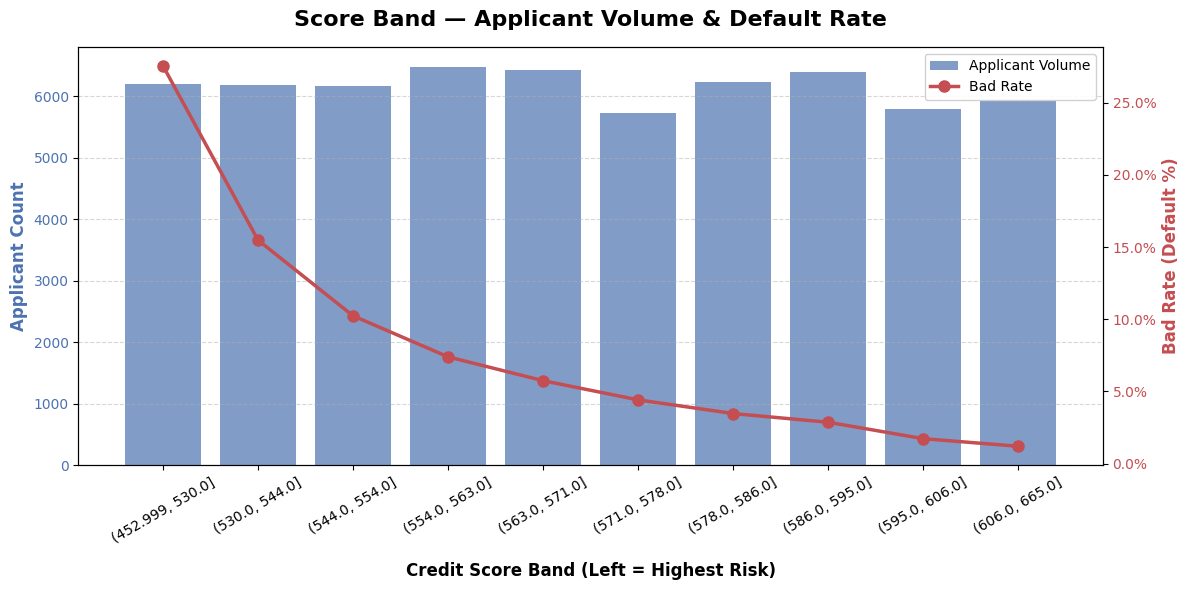

Saved → a:\Dominic\My Projects\Home Credit\data\Model-Training\ScoreOutput\score_band_chart.png
  Score_Band_Str  Applicant_Count  Bad_Count  Bad_Rate
(452.999, 530.0]             6194       1707  0.275589
  (530.0, 544.0]             6174        956  0.154843
  (544.0, 554.0]             6163        631  0.102385
  (554.0, 563.0]             6478        479  0.073943
  (563.0, 571.0]             6424        369  0.057441
  (571.0, 578.0]             5732        253  0.044138
  (578.0, 586.0]             6231        216  0.034665
  (586.0, 595.0]             6390        183  0.028638
  (595.0, 606.0]             5794        100  0.017259
  (606.0, 665.0]             5923         71  0.011987


In [ ]:
predictions_df['Score_Band'] = pd.qcut(
    predictions_df['score'], q=10, duplicates='drop'
)

summary = predictions_df.groupby('Score_Band', observed=True).agg(
    Applicant_Count=('TARGET', 'count'),
    Bad_Count=('TARGET', 'sum'),
).reset_index()
summary['Bad_Rate']      = summary['Bad_Count'] / summary['Applicant_Count']
summary['Score_Band_Str'] = summary['Score_Band'].astype(str)

fig, ax1 = plt.subplots(figsize=(12, 6))

COLOR_BAR  = '#4C72B0'
COLOR_LINE = '#C44E52'

ax1.bar(summary['Score_Band_Str'], summary['Applicant_Count'],
        color=COLOR_BAR, alpha=0.7, label='Applicant Volume')
ax1.set_xlabel('Credit Score Band (Left = Highest Risk)', fontsize=12,
               fontweight='bold', labelpad=12)
ax1.set_ylabel('Applicant Count', color=COLOR_BAR, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=COLOR_BAR)
ax1.tick_params(axis='x', rotation=30)

ax2 = ax1.twinx()
ax2.plot(summary['Score_Band_Str'], summary['Bad_Rate'],
         color=COLOR_LINE, marker='o', markersize=8, linewidth=2.5, label='Bad Rate')
ax2.set_ylabel('Bad Rate (Default %)', color=COLOR_LINE, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=COLOR_LINE)
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.title('Score Band — Applicant Volume & Default Rate', fontsize=16,
          fontweight='bold', pad=15)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.show()

print(summary[['Score_Band_Str', 'Applicant_Count', 'Bad_Count', 'Bad_Rate']].to_string(index=False))

## 7. Score Distribution Histogram

> **Note:** The x-axis limits
> are now set from `MIN_SCORE` / `MAX_SCORE` so the full configured range is always shown.

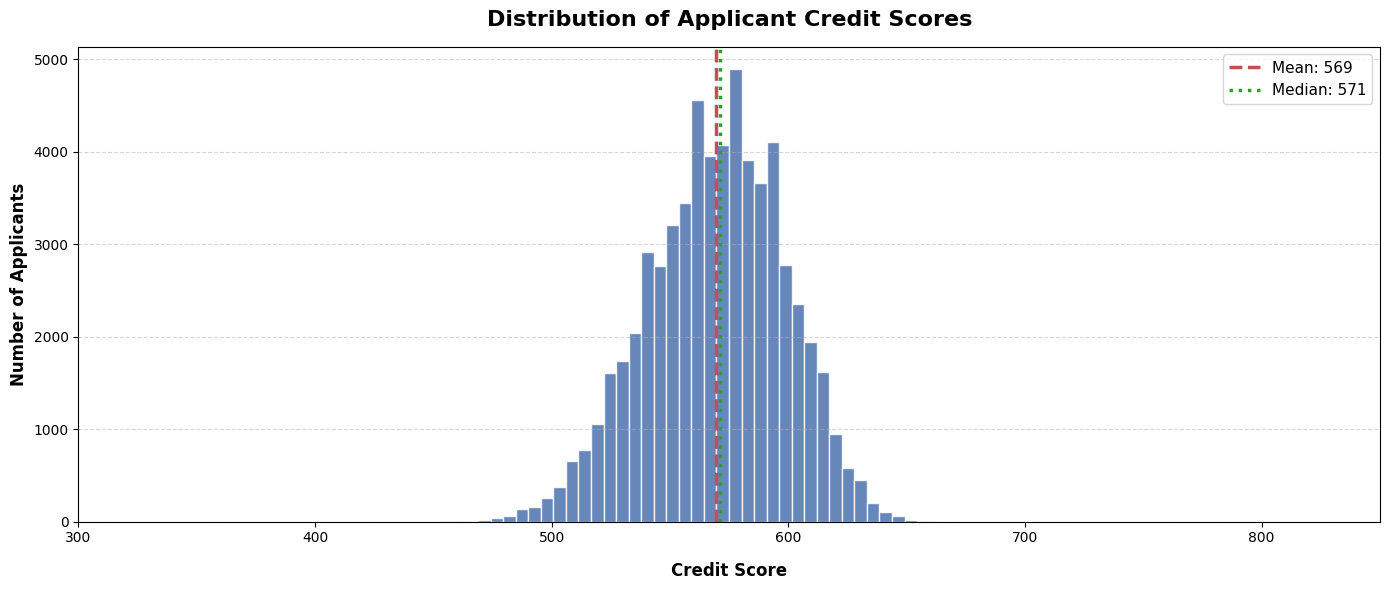

Saved → a:\Dominic\My Projects\Home Credit\data\Model-Training\ScoreOutput\score_distribution.png


In [ ]:
fig2, ax = plt.subplots(figsize=(14, 6))

ax.hist(predictions_df['score'], bins=40, color='#4C72B0', edgecolor='white', alpha=0.85)

mean_score   = predictions_df['score'].mean()
median_score = predictions_df['score'].median()
ax.axvline(mean_score,   color='#C44E52', linestyle='dashed', linewidth=2.5,
           label=f'Mean: {mean_score:.0f}')
ax.axvline(median_score, color='#2CA02C', linestyle='dotted', linewidth=2.5,
           label=f'Median: {median_score:.0f}')

# FIX: xlim from config constants, not hardcoded 400-700
ax.set_xlim(MIN_SCORE, MAX_SCORE)
ax.set_title('Distribution of Applicant Credit Scores', fontsize=16,
             fontweight='bold', pad=15)
ax.set_xlabel('Credit Score', fontsize=12, fontweight='bold', labelpad=12)
ax.set_ylabel('Number of Applicants', fontsize=12, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

## 8. KS Statistic

The Kolmogorov-Smirnov (KS) statistic measures the maximum separation between the
cumulative distribution of scores for defaulters vs. non-defaulters. A higher KS
means the model better separates the two groups.

General benchmarks (credit risk context):
- KS < 20: poor discrimination
- KS 20–40: acceptable
- KS 40–60: good
- KS > 60: excellent (verify for overfitting)

> **Note:** KS is computed on every individual record using `scipy.stats.ks_2samp` — the mathematically
> correct approach — followed by the traditional KS table on the decile bands
> for business reporting.

In [37]:
# FIX: compute KS on all individual records, not aggregated buckets
scores_good = predictions_df.loc[predictions_df['TARGET'] == 0, 'score']
scores_bad  = predictions_df.loc[predictions_df['TARGET'] == 1, 'score']

ks_result = stats.ks_2samp(scores_good, scores_bad)
print(f"KS Statistic (scipy, record-level) : {ks_result.statistic * 100:.2f}")
print(f"p-value                             : {ks_result.pvalue:.2e}")
print()

KS Statistic (scipy, record-level) : 39.60
p-value                             : 0.00e+00



In [38]:
# KS table on decile bands — useful for business reporting and scorecard documentation
summary['Good_Count']  = summary['Applicant_Count'] - summary['Bad_Count']
summary['Bad_Pct']     = summary['Bad_Count']  / summary['Bad_Count'].sum()
summary['Good_Pct']    = summary['Good_Count'] / summary['Good_Count'].sum()
summary['Cum_Bad_Pct'] = summary['Bad_Pct'].cumsum()
summary['Cum_Good_Pct']= summary['Good_Pct'].cumsum()
summary['KS_Spread']   = (summary['Cum_Bad_Pct'] - summary['Cum_Good_Pct']).abs() * 100

ks_band = summary.loc[summary['KS_Spread'].idxmax(), 'Score_Band_Str']
print(f"KS Statistic (decile table)         : {summary['KS_Spread'].max():.2f}")
print(f"Maximum separation at score band    : {ks_band}")
print()
print('--- Decile KS Table ---')
ks_cols = ['Score_Band_Str', 'Applicant_Count', 'Bad_Rate',
           'Cum_Bad_Pct', 'Cum_Good_Pct', 'KS_Spread']
print(summary[ks_cols].to_string(index=False, float_format='{:.4f}'.format))

KS Statistic (decile table)         : 39.39
Maximum separation at score band    : (544.0, 554.0]

--- Decile KS Table ---
  Score_Band_Str  Applicant_Count  Bad_Rate  Cum_Bad_Pct  Cum_Good_Pct  KS_Spread
(452.999, 530.0]             6194    0.2756       0.3438        0.0794    26.4444
  (530.0, 544.0]             6174    0.1548       0.5364        0.1717    36.4700
  (544.0, 554.0]             6163    0.1024       0.6634        0.2695    39.3944
  (554.0, 563.0]             6478    0.0739       0.7599        0.3756    38.4314
  (563.0, 571.0]             6424    0.0574       0.8342        0.4827    35.1538
  (571.0, 578.0]             5732    0.0441       0.8852        0.5796    30.5586
  (578.0, 586.0]             6231    0.0347       0.9287        0.6860    24.2702
  (586.0, 595.0]             6390    0.0286       0.9656        0.7958    16.9776
  (595.0, 606.0]             5794    0.0173       0.9857        0.8965     8.9206
  (606.0, 665.0]             5923    0.0120       1.0000  

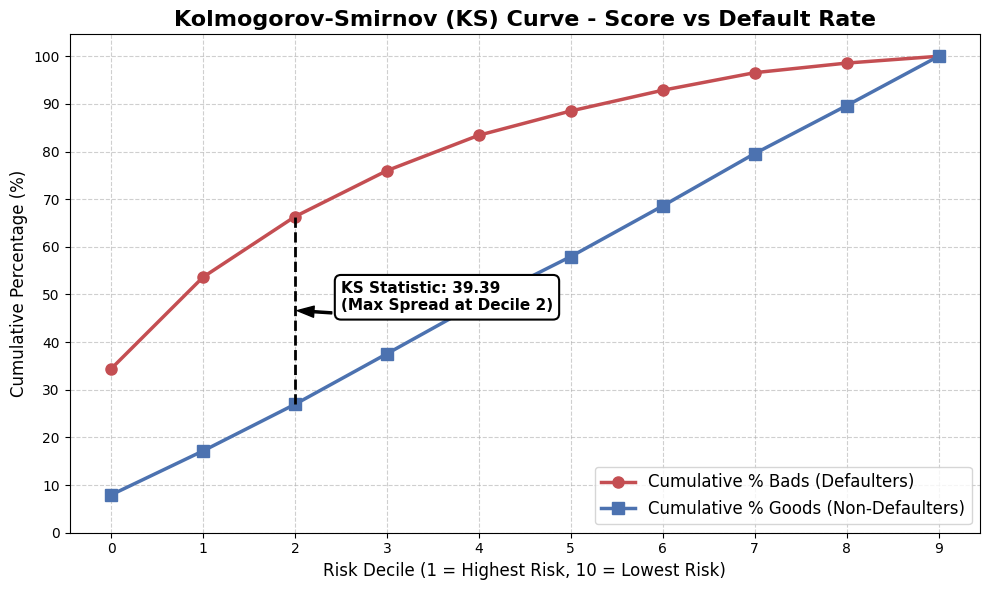

In [ ]:
# ==============================================================================
# 4. PLOTTING THE KS CURVE
# ==============================================================================

# Extract the data from the ks_table we built in the previous step
deciles = summary.index.values
cum_bads = summary['Cum_Bad_Pct'] * 100
cum_goods = summary['Cum_Good_Pct'] * 100
ks_spread = summary['KS_Spread']

# Find the decile where the KS statistic (maximum spread) occurs
ks_max_decile = ks_spread.idxmax()
ks_max_bad = cum_bads[ks_max_decile]
ks_max_good = cum_goods[ks_max_decile]
ks_stat_value = ks_spread[ks_max_decile]

# Create the plot
fig_ks, ax = plt.subplots(figsize=(10, 6))

# Plot the cumulative curves
ax.plot(deciles, cum_bads, marker='o', color='#C44E52', linewidth=2.5, markersize=8, label='Cumulative % Bads (Defaulters)')
ax.plot(deciles, cum_goods, marker='s', color='#4C72B0', linewidth=2.5, markersize=8, label='Cumulative % Goods (Non-Defaulters)')

# Draw a vertical dashed line to highlight the KS gap
ax.vlines(x=ks_max_decile, ymin=ks_max_good, ymax=ks_max_bad, color='black', 
          linestyle='--', linewidth=2, zorder=3)

# Add an annotation pointing to the KS gap
ax.annotate(f'KS Statistic: {ks_stat_value:.2f}\n(Max Spread at Decile {ks_max_decile})', 
            xy=(ks_max_decile, (ks_max_bad + ks_max_good) / 2), 
            xytext=(ks_max_decile + 0.5, (ks_max_bad + ks_max_good) / 2),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
            fontsize=11, fontweight='bold', 
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="black", lw=1.5))

# Formatting the chart
ax.set_title('Kolmogorov-Smirnov (KS) Curve - Score vs Default Rate', fontsize=16, fontweight='bold')
ax.set_xlabel('Risk Decile (1 = Highest Risk, 10 = Lowest Risk)', fontsize=12)
ax.set_ylabel('Cumulative Percentage (%)', fontsize=12)

# Ensure X-axis only shows whole numbers 1 through 10
ax.set_xticks(deciles)
# Ensure Y-axis goes from 0 to 100 with steps of 10
ax.set_yticks(np.arange(0, 110, 10))

ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='lower right', fontsize=12)

plt.tight_layout()
plt.show()

## 9. Save Outputs

In [42]:
cols_to_convert = ['Risk_Band', 'Score_Band']
predictions_df[cols_to_convert] = predictions_df[cols_to_convert].astype(str)

In [ ]:
# Full scored predictions — one row per applicant
predictions_df.to_parquet(os.path.join(SCORE_DIR, "scored_predictions.parquet"), index=False)
print(f"Saved scored predictions → {os.path.join(SCORE_DIR, 'scored_predictions.parquet')}")

# Scoreband summary table (decile + risk band)
summary.to_csv(os.path.join(SCORE_DIR, "scoreband_summary.csv"), index=False)
print(f"Saved scoreband summary  → {os.path.join(SCORE_DIR, 'scoreband_summary.csv')}")

fig.savefig(os.path.join(SCORE_DIR, "score_band_chart.png"), dpi=150, bbox_inches='tight')
print(f"Saved score band chart → {os.path.join(SCORE_DIR, 'score_band_chart.png')}")

fig2.savefig(os.path.join(SCORE_DIR, "score_distribution.png"), dpi=150, bbox_inches='tight')
print(f"Saved score distribution → {os.path.join(SCORE_DIR, 'score_distribution.png')}")

fig_ks.savefig(os.path.join(SCORE_DIR, 'KS_Curve_Score.png'), dpi=150, bbox_inches='tight')
print(f"Saved KS curve  → {os.path.join(SCORE_DIR, 'KS_Curve_Score.png')}")

print(f"\nFinal scored dataset shape: {predictions_df.shape}")
print(f"Columns: {predictions_df.columns.tolist()}")

Saved scored predictions → a:\Dominic\My Projects\Home Credit\data\Model-Training\ScoreOutput\scored_predictions.parquet
Saved scoreband summary  → a:\Dominic\My Projects\Home Credit\data\Model-Training\ScoreOutput\scoreband_summary.csv

Final scored dataset shape: (61503, 6)
Columns: ['SK_ID_CURR', 'TARGET', 'predicted_proba', 'score', 'Risk_Band', 'Score_Band']


## 10. Cleanup

In [27]:
del predictions_df, summary
import gc; gc.collect()
print("All DataFrames released.")

All DataFrames released.
